
Important assumptions:

1) I could not find proper S&P500 monthly return data since 1970 -- I have checked several sources and each has issues.
    Instead, I have used Ken French US market return (CRSP value-weighted, including dividends), the correlation with S&P500 is close to .99

2) I also could not find bond monthly 10y bond returns for such a long period, the return is instead defined as:
r_t = P_t − 1 + y_{t−1} / 12 (monthly return = price change of a par bond bought last month + one month of coupon income at last month’s yield)


In [4]:
import pandas as pd
import pandas_datareader.data as web
import matplotlib.pyplot as plt

START = "1969-12"

ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START)[0] / 100
df_eq = pd.DataFrame({"eq_ret": ff["Mkt-RF"] + ff["RF"], "rf": ff["RF"]})

fred = web.DataReader(["DGS10", "CPIAUCSL"], "fred", start=START)
y = fred["DGS10"].dropna().resample("ME").last() / 100
y.index = y.index.to_period("M")

disc = (1 + y / 2) ** (-2 * (10 - 1 / 12))
price = (y.shift(1) / y) * (1 - disc) + disc
df_bond = pd.DataFrame({"y10": y, "bond_ret": price - 1 + y.shift(1) / 12})

df_cpi = fred[["CPIAUCSL"]].dropna().rename(columns={"CPIAUCSL": "cpi"})
df_cpi.index = df_cpi.index.to_period("M")

df = pd.concat([df_eq, df_bond, df_cpi], axis=1).loc["1970-01":].dropna()

df["infl_12m"] = df["cpi"].pct_change(12)
df["infl_24m"] = (df["cpi"] / df["cpi"].shift(24)) ** 0.5 - 1





/var/folders/fn/xnv_3pc51kdd4glszktsxpp40000gn/T/ipykernel_30724/3313520511.py:7: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START)[0] / 100
/var/folders/fn/xnv_3pc51kdd4glszktsxpp40000gn/T/ipykernel_30724/3313520511.py:7: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  ff = web.DataReader("F-F_Research_Data_Factors", "famafrench", start=START)[0] / 100


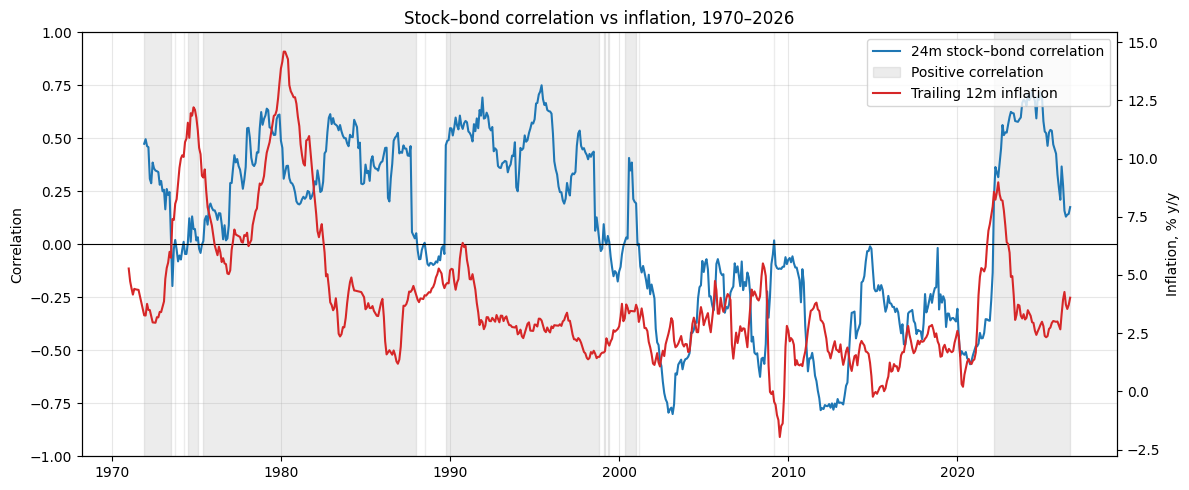

corr_24m
positive    55.1%
negative    44.9%
Name: proportion, dtype: object

All periods:
  regime   start     end  months
positive 1971-12 1973-07      20
negative 1973-08 1973-09       2
positive 1973-10 1973-10       1
negative 1973-11 1974-03       5
positive 1974-04 1974-04       1
negative 1974-05 1974-06       2
positive 1974-07 1975-02       8
negative 1975-03 1975-05       3
positive 1975-06 1988-01     152
negative 1988-02 1988-06       5
positive 1988-07 1988-07       1
negative 1988-08 1989-09      14
positive 1989-10 1998-11     110
negative 1998-12 1999-01       2
positive 1999-02 1999-03       2
negative 1999-04 1999-04       1
positive 1999-05 1999-06       2
negative 1999-07 2000-04      10
positive 2000-05 2001-01       9
negative 2001-02 2001-02       1
positive 2001-03 2001-03       1
negative 2001-04 2009-02      95
positive 2009-03 2009-03       1
negative 2009-04 2022-02     155
positive 2022-03 2026-09      54

Positive periods (6+ months):
  regime   start    

In [17]:
import matplotlib.pyplot as plt

df["corr_24m"] = df["eq_ret"].rolling(24).corr(df["bond_ret"])
df["infl_12m"] = df["cpi"].pct_change(12)


regime = df["corr_24m"].dropna().gt(0).map({True: "positive", False: "negative"})

block = (regime != regime.shift()).cumsum()
periods = (regime.groupby(block)
           .agg(regime="first",
                start=lambda r: r.index[0],
                end=lambda r: r.index[-1],
                months="size")
           .reset_index(drop=True))


x = df.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(x, df["corr_24m"], color="tab:blue", label="24m stock–bond correlation")
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_ylabel("Correlation")
ax1.set_ylim(-1, 1)

ax2 = ax1.twinx()
ax2.plot(x, df["infl_12m"] * 100, color="tab:red", label="Trailing 12m inflation")
ax2.set_ylabel("Inflation, % y/y")

ax1.fill_between(x, -1, 1, where=df["corr_24m"] > 0,
                 color="grey", alpha=0.15, label="Positive correlation")

lines = ax1.get_legend_handles_labels()
lines2 = ax2.get_legend_handles_labels()
ax1.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="upper right")

ax1.set_title("Stock–bond correlation vs inflation, 1970–2026")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

share = regime.value_counts(normalize=True) * 100
print(share.round(1).astype(str) + "%")

print("\nAll periods:")
print(periods.to_string(index=False))

print("\nPositive periods (6+ months):")
print(periods.query("regime == 'positive' and months >= 6").to_string(index=False))

print("\nNegative periods (6+ months):")
print(periods.query("regime == 'negative' and months >= 6").to_string(index=False))

In [18]:

df["infl_24m"] = (df["cpi"] / df["cpi"].shift(24)) ** 0.5 - 1

a = df.loc[regime.index].copy()
a["regime"] = regime


print("1. Inflation by regime, % per year")
print((a.groupby("regime")[["infl_12m", "infl_24m"]]
         .agg(["mean", "median"]) * 100).round(2))


bins = [-1, 0.02, 0.03, 0.05, 1]
labels = ["<2%", "2–3%", "3–5%", ">5%"]
a["infl_bucket"] = pd.cut(a["infl_24m"], bins=bins, labels=labels)

print("\n2. Correlation by inflation bucket")
print(a.groupby("infl_bucket").agg(
    mean_corr=("corr_24m", "mean"),
    share_positive=("corr_24m", lambda c: (c > 0).mean()),
    months=("corr_24m", "size"),
).round(2))


def period_infl(row):
    return a.loc[row["start"]:row["end"], "infl_24m"].mean() * 100

p = periods.query("months >= 6").copy()
p["avg_infl_24m_%"] = p.apply(period_infl, axis=1).round(2)
print("\n3. Inflation per period")
print(p.to_string(index=False))

1. Inflation by regime, % per year
         infl_12m        infl_24m       
             mean median     mean median
regime                                  
negative     2.69   2.25     2.51   2.26
positive     4.98   3.70     5.14   4.00

2. Correlation by inflation bucket
             mean_corr  share_positive  months
infl_bucket                                   
<2%              -0.26            0.11     115
2–3%             -0.03            0.46     211
3–5%              0.19            0.63     182
>5%               0.33            0.92     148

3. Inflation per period
  regime   start     end  months  avg_infl_24m_%
positive 1971-12 1973-07      20            3.90
positive 1974-07 1975-02       8            9.91
positive 1975-06 1988-01     152            6.83
negative 1988-08 1989-09      14            4.39
positive 1989-10 1998-11     110            3.32
negative 1999-07 2000-04      10            2.22
positive 2000-05 2001-01       9            2.95
negative 2001-04 2009-02 

/var/folders/fn/xnv_3pc51kdd4glszktsxpp40000gn/T/ipykernel_21376/2617354331.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(a.groupby("infl_bucket").agg(


In [19]:
df["infl_m"] = df["cpi"].pct_change()
df["eq_real"] = (1 + df["eq_ret"]) / (1 + df["infl_m"]) - 1
df["bond_real"] = (1 + df["bond_ret"]) / (1 + df["infl_m"]) - 1
df["p6040"] = 0.6 * df["eq_real"] + 0.4 * df["bond_real"]

b = df.loc[regime.index, ["p6040"]].copy()
b["regime"] = regime
b["block"] = block

def drawdown(r):
    value = (1 + r).cumprod()
    return value / value.cummax() - 1


b["dd"] = b.groupby("block")["p6040"].transform(drawdown)

summary = b.groupby("regime").agg(
    months=("p6040", "size"),
    mean_real_ann=("p6040", lambda r: (1 + r.mean()) ** 12 - 1),
    vol_ann=("p6040", lambda r: r.std() * 12 ** 0.5),
    max_dd=("dd", "min"),
    avg_dd=("dd", "mean"),
    pct_underwater=("dd", lambda x: (x < 0).mean()),
)
print((summary * [1, 100, 100, 100, 100, 100]).round(2))

          months  mean_real_ann  vol_ann  max_dd  avg_dd  pct_underwater
regime                                                                  
negative     295           5.30     8.81  -29.97   -2.17           57.29
positive     362           6.62    11.48  -20.33   -4.27           66.02


Findings:

1) During high-inflation regimes (1971–1998, 2022–2026), stocks and bonds show positive correlation. During the low-inflation regime (2001–2022), the correlation is negative. The switch happens at about 2–3% inflation. Thus, bonds hedge stocks only during low-inflation periods.

2) During the positive-correlation regime, the 60/40 portfolio shows higher volatility (11.5% vs 8.8%), average drawdowns about twice as deep (−4.3% vs −2.2%), and more time underwater (66% vs 57% of months). The largest single drawdown (−30%, 2008) occurs in the negative-correlation regime, as the equity crash was too large for bonds to offset.